# 3D Brain Tumor Segmentation — Pre-trained UNet3D vs UNETR on BraTS-Africa

End-to-end **inference-only** notebook for
[Brain_Tumor_Benchmark](https://github.com/MohanadMahran/Brain_Tumor_Benchmark).

* Loads the **pre-trained** checkpoints (no training, no fine-tuning).
* Runs them on real tumour cases from the **BraTS-Africa** dataset.
* Reports **Dice** and **HD95** per region (ET / TC / WT).
* Renders axial slices: T1ce input, ground truth, and both model predictions.

| Section | What happens |
|---|---|
| 0. Setup | Install deps, pick device (GPU if available), seed |
| 1. Models | `UNet3D` and `UNETR` — inlined verbatim from the repo |
| 2. Preprocessing + Metrics | NIfTI Z-score pipeline and Dice/HD95 — inlined verbatim from the repo |
| 3. Weights | Load pre-trained checkpoints **strictly** from the attached Kaggle dataset |
| 4. Dataset | Discover BraTS-Africa cases (`t1n`/`t1c`/`t2w`/`t2f`/`seg`) |
| 5. Inference | Sliding-window inference (roi 128^3) for both models |
| 6. Results | Per-case metrics table, aggregate table, CSV |
| 7. Figures | Axial slice overlays: T1ce / GT / UNet3D / UNETR |

**Attached datasets**

| Dataset | Purpose |
|---|---|
| `zekrock/brats-weights` | Pre-trained checkpoints (UNet3D + UNETR) |
| `yakunokamizen/brats-africa` | BraTS-Africa cases (146 volumes with ground-truth segmentations) |


In [1]:
# ============================================================
# 0. SETUP — dependencies, device, seed
# ============================================================
# MONAI is optional; the tested fallback does not require a network install.
import importlib.util, subprocess, sys
if importlib.util.find_spec("monai") is None:
    install = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                              "--retries", "0", "--timeout", "15", "monai"],
                             capture_output=True, text=True)
    if install.returncode:
        print("MONAI could not be installed; using the tested built-in sliding window.")

import os, time, random, logging
import json, hashlib, platform
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
REQUIRE_GPU = True
if REQUIRE_GPU and DEVICE.type != "cuda":
    raise RuntimeError("GPU requested but CUDA is unavailable. Verify Kaggle account access, select GPU T4 x2, and start a new session. Set REQUIRE_GPU=False only for an intentional CPU run.")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = False


def set_global_seed(seed: int = 42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(42)
print("Device:", DEVICE, "| torch:", torch.__version__,
      "| cuda build:", torch.version.cuda if DEVICE.type == "cuda" else "N/A")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Input root:", Path("/kaggle/input"))
for p in sorted(Path("/kaggle/input").glob("*")):
    sub = sorted(q.name for q in p.iterdir()) if p.is_dir() else ["<file>"]
    print(f"  attached: {p.name} -> {sub[:12]}")


Device: cuda | torch: 2.11.0+cu128 | cuda build: 12.8
GPU: Tesla T4
Input root: /kaggle/input
  attached: datasets -> ['yakunokamizen', 'zekrock']


## 1. Model architectures — inlined verbatim from the repo

These are the exact classes the pre-trained weights were saved against, so
`load_state_dict(..., strict=True)` succeeds in section 3.

In [2]:
# ============================================================
# 1a. 3D U-Net — repo/models/unet3d.py (verbatim)
# ============================================================
"""3D U-Net implementation for brain tumor segmentation.

Architecture:
    - Encoder: 4 levels of double conv blocks (GroupNorm + LeakyReLU)
    - Channel progression: 4 -> 32 -> 64 -> 128 -> 256
    - Downsampling: MaxPool3d(2,2,2)
    - Decoder: Transposed conv upsampling + skip concatenation
    - Output: 3 sigmoid channels (ET, TC, WT)
    - NO BatchNorm — uses GroupNorm(groups=8) exclusively
    - Stochastic depth (drop path) for regularization

Target: ~19M parameters.
"""

import logging
from typing import List

import torch
import torch.nn as nn
import torch.nn.functional as F

logger = logging.getLogger(__name__)


class DropPath(nn.Module):
    """Drop path (stochastic depth) for regularization.

    Randomly drops entire residual branches during training.

    Args:
        drop_prob: Probability of dropping the path.
    """

    def __init__(self, drop_prob: float = 0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor = torch.floor(random_tensor + keep_prob)
        output = x / keep_prob * random_tensor
        return output


class ConvBlock(nn.Module):
    """Double 3D convolution block with GroupNorm and LeakyReLU.

    Each block: Conv3d -> GroupNorm -> LeakyReLU -> Conv3d -> GroupNorm -> LeakyReLU
    With optional residual connection and drop path.

    Args:
        in_channels: Number of input channels.
        out_channels: Number of output channels.
        groups: Number of groups for GroupNorm.
        dropout: Dropout probability.
        drop_path_rate: Stochastic depth rate.
    """

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        groups: int = 8,
        dropout: float = 0.0,
        drop_path_rate: float = 0.0,
    ):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.gn1 = nn.GroupNorm(groups, out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.gn2 = nn.GroupNorm(groups, out_channels)
        self.act = nn.LeakyReLU(inplace=True)
        self.dropout = nn.Dropout3d(p=dropout) if dropout > 0 else nn.Identity()
        self.drop_path = DropPath(drop_path_rate) if drop_path_rate > 0 else nn.Identity()

        # Residual connection (1x1 conv if channels change)
        self.residual = (
            nn.Conv3d(in_channels, out_channels, kernel_size=1, bias=False)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.residual(x)
        out = self.conv1(x)
        out = self.gn1(out)
        out = self.act(out)
        out = self.dropout(out)
        out = self.conv2(out)
        out = self.gn2(out)

        # Apply drop path to the residual branch
        out = self.drop_path(out) + residual
        out = self.act(out)
        return out


class Encoder(nn.Module):
    """4-level 3D U-Net encoder.

    Args:
        in_channels: Input channels (4 for BraTS).
        base_channels: Base channel count.
        groups: GroupNorm groups.
        dropout_rates: Per-level dropout rates.
        drop_path_rate: Maximum drop path rate.
    """

    def __init__(
        self,
        in_channels: int = 4,
        base_channels: int = 32,
        groups: int = 8,
        dropout_rates: List[float] = None,
        drop_path_rate: float = 0.1,
    ):
        super().__init__()
        if dropout_rates is None:
            dropout_rates = [0.1, 0.2, 0.2, 0.2]

        channels = [base_channels, base_channels * 2, base_channels * 4, base_channels * 8]

        # Linearly increasing drop path rates
        dpr = [drop_path_rate * i / 3 for i in range(4)]

        self.blocks = nn.ModuleList()
        self.pools = nn.ModuleList()

        # Level 0
        self.blocks.append(
            ConvBlock(in_channels, channels[0], groups, dropout_rates[0], dpr[0])
        )

        # Levels 1-3
        for i in range(1, 4):
            self.pools.append(nn.MaxPool3d(kernel_size=2, stride=2))
            self.blocks.append(
                ConvBlock(channels[i - 1], channels[i], groups, dropout_rates[i], dpr[i])
            )

    def forward(self, x: torch.Tensor) -> List[torch.Tensor]:
        """Forward pass returning skip connections at each level.

        Returns:
            List of feature maps [level0, level1, level2, level3(bottleneck)].
        """
        features = []
        out = self.blocks[0](x)
        features.append(out)

        for i in range(1, 4):
            out = self.pools[i - 1](out)
            out = self.blocks[i](out)
            features.append(out)

        return features


class Decoder(nn.Module):
    """3D U-Net decoder with transposed convolution upsampling.

    Args:
        base_channels: Base channel count (same as encoder).
        groups: GroupNorm groups.
    """

    def __init__(self, base_channels: int = 32, groups: int = 8):
        super().__init__()
        channels = [base_channels, base_channels * 2, base_channels * 4, base_channels * 8]

        # Upsampling blocks (from bottleneck up)
        self.up_convs = nn.ModuleList()
        self.conv_blocks = nn.ModuleList()

        for i in range(2, -1, -1):  # levels 2, 1, 0
            self.up_convs.append(
                nn.ConvTranspose3d(
                    channels[i + 1], channels[i], kernel_size=2, stride=2
                )
            )
            # After concatenation with skip: channels[i]*2 -> channels[i]
            self.conv_blocks.append(
                ConvBlock(channels[i] * 2, channels[i], groups)
            )

    def forward(self, features: List[torch.Tensor]) -> torch.Tensor:
        """Decode from bottleneck using skip connections.

        Args:
            features: List [level0, level1, level2, bottleneck] from encoder.

        Returns:
            Decoded feature map at original resolution.
        """
        x = features[-1]  # Bottleneck

        for i, (up_conv, conv_block) in enumerate(zip(self.up_convs, self.conv_blocks)):
            x = up_conv(x)
            skip = features[-(i + 2)]  # Corresponding skip connection

            # Handle size mismatches from non-power-of-2 dimensions
            if x.shape != skip.shape:
                x = F.interpolate(x, size=skip.shape[2:], mode='trilinear', align_corners=False)

            x = torch.cat([x, skip], dim=1)
            x = conv_block(x)

        return x


class UNet3D(nn.Module):
    """3D U-Net for brain tumor segmentation.

    Architecture:
        - 4-level encoder with GroupNorm and LeakyReLU
        - Skip connections via concatenation
        - Transposed conv decoder
        - 3-channel sigmoid output (ET, TC, WT)
        - Stochastic depth regularization

    Target: ~19M parameters.

    Args:
        in_channels: Input channels (4 for T1, T1ce, T2, FLAIR).
        out_channels: Output channels (3 for ET, TC, WT).
        base_channels: Base channel width.
        groups: GroupNorm number of groups.
        dropout_rates: Per-encoder-level dropout rates.
        drop_path_rate: Maximum stochastic depth rate.
    """

    def __init__(
        self,
        in_channels: int = 4,
        out_channels: int = 3,
        base_channels: int = 32,
        groups: int = 8,
        dropout_rates: List[float] = None,
        drop_path_rate: float = 0.1,
    ):
        super().__init__()
        if dropout_rates is None:
            dropout_rates = [0.1, 0.2, 0.2, 0.2]

        self.encoder = Encoder(
            in_channels=in_channels,
            base_channels=base_channels,
            groups=groups,
            dropout_rates=dropout_rates,
            drop_path_rate=drop_path_rate,
        )
        self.decoder = Decoder(base_channels=base_channels, groups=groups)

        # Output head: 1x1x1 conv to desired channels
        self.output_conv = nn.Conv3d(base_channels, out_channels, kernel_size=1)

        # Initialize weights
        self._init_weights()

        logger.info(
            f"UNet3D initialized: in={in_channels}, out={out_channels}, "
            f"base_ch={base_channels}, groups={groups}"
        )

    def _init_weights(self):
        """Initialize weights: Kaiming normal for conv, constant 1 for GroupNorm."""
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='leaky_relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass.

        Args:
            x: Input tensor of shape (B, 4, D, H, W).

        Returns:
            Logits tensor of shape (B, 3, D, H, W).
            Apply sigmoid externally for probability maps.
        """
        features = self.encoder(x)
        decoded = self.decoder(features)
        logits = self.output_conv(decoded)
        return logits

    def forward_with_sigmoid(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass with sigmoid activation for inference.

        Args:
            x: Input tensor of shape (B, 4, D, H, W).

        Returns:
            Probability tensor of shape (B, 3, D, H, W) in [0, 1].
        """
        return torch.sigmoid(self.forward(x))


In [3]:
# ============================================================
# 1b. UNETR — repo/models/unetr.py (verbatim)
# ============================================================
"""UNETR implementation for brain tumor segmentation.

Architecture:
    - Patch embedding: 16³ non-overlapping patches (dynamic token count)
    - Transformer: 6 layers, 8 heads, embedding_dim=384
    - Pre-norm with LayerNorm
    - Gradient checkpointing on all transformer layers
    - CNN decoder with skip connections from layers 3 and 6
    - Stochastic depth (drop path) regularization
    - NO BatchNorm — LayerNorm exclusively
    - Dynamic positional embedding interpolation for variable input sizes

Target: ~19M parameters.
"""

import logging
from functools import partial
from typing import List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

logger = logging.getLogger(__name__)


class DropPath(nn.Module):
    """Drop path (stochastic depth) regularization."""

    def __init__(self, drop_prob: float = 0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor = torch.floor(random_tensor + keep_prob)
        return x / keep_prob * random_tensor


class PatchEmbedding3D(nn.Module):
    """3D Patch Embedding for volumetric data.

    Divides input volume into non-overlapping patches and projects
    each flattened patch to the embedding dimension.

    Positional embeddings are allocated at init for the given input_size,
    but dynamically interpolated in forward() if the actual input produces
    a different number of tokens (e.g., input_size=128 with patch_size=16
    produces 8^3=512 tokens).

    Args:
        in_channels: Input channels (4 for BraTS).
        patch_size: Patch dimensions (e.g., 16).
        embedding_dim: Token embedding dimension.
        input_size: Input spatial dimensions used to initialize pos_embed.
    """

    def __init__(
        self,
        in_channels: int = 4,
        patch_size: int = 16,
        embedding_dim: int = 256,
        input_size: int = 96,
    ):
        super().__init__()
        self.patch_size = patch_size
        self.embedding_dim = embedding_dim
        self.init_grid_size = input_size // patch_size
        self.init_num_patches = self.init_grid_size ** 3

        # Linear projection via Conv3d with kernel_size = stride = patch_size
        self.proj = nn.Conv3d(
            in_channels,
            embedding_dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        # Learnable absolute positional embeddings
        self.pos_embed = nn.Parameter(
            torch.zeros(1, self.init_num_patches, embedding_dim)
        )
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def _interpolate_pos_embed(
        self, pos_embed: torch.Tensor, grid_size: int
    ) -> torch.Tensor:
        """Interpolate positional embeddings to match actual grid size.

        Reshapes the 1D token sequence to a 3D grid, applies trilinear
        interpolation, then flattens back.

        Args:
            pos_embed: Shape (1, init_num_patches, embedding_dim).
            grid_size: Actual grid size (tokens per spatial dimension).

        Returns:
            Interpolated pos_embed of shape (1, grid_size^3, embedding_dim).
        """
        g0 = self.init_grid_size
        # (1, g0^3, D) -> (1, D, g0, g0, g0)
        pos_embed = pos_embed.transpose(1, 2).reshape(
            1, self.embedding_dim, g0, g0, g0
        )
        # Interpolate to new grid size
        pos_embed = F.interpolate(
            pos_embed,
            size=(grid_size, grid_size, grid_size),
            mode="trilinear",
            align_corners=False,
        )
        # (1, D, g, g, g) -> (1, g^3, D)
        pos_embed = pos_embed.flatten(2).transpose(1, 2)
        return pos_embed

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Convert volume to sequence of patch embeddings.

        Args:
            x: Input of shape (B, C, D, H, W).

        Returns:
            Token sequence of shape (B, num_patches, embedding_dim).
        """
        # (B, C, D, H, W) -> (B, embed_dim, D', H', W')
        x = self.proj(x)
        B, D_emb, gD, gH, gW = x.shape
        actual_grid_size = gD  # assumes cubic input: gD == gH == gW

        # (B, embed_dim, D', H', W') -> (B, embed_dim, num_patches)
        x = x.flatten(2)
        # (B, embed_dim, num_patches) -> (B, num_patches, embed_dim)
        x = x.transpose(1, 2)

        # Interpolate positional embeddings if token count changed
        if actual_grid_size != self.init_grid_size:
            pos_embed = self._interpolate_pos_embed(self.pos_embed, actual_grid_size)
        else:
            pos_embed = self.pos_embed

        x = x + pos_embed
        return x


class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention with pre-norm.

    Args:
        embedding_dim: Token embedding dimension.
        num_heads: Number of attention heads.
        dropout: Attention dropout rate.
    """

    def __init__(self, embedding_dim: int = 256, num_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        assert embedding_dim % num_heads == 0, "embedding_dim must be divisible by num_heads"
        self.num_heads = num_heads
        self.head_dim = embedding_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(embedding_dim, embedding_dim * 3)
        self.proj = nn.Linear(embedding_dim, embedding_dim)
        self.attn_drop = nn.Dropout(dropout)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Compute multi-head self-attention.

        Args:
            x: Token sequence of shape (B, N, D).

        Returns:
            Attended tokens of shape (B, N, D).
        """
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, heads, N, head_dim)
        q, k, v = qkv.unbind(0)

        # Scaled dot-product attention
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B, N, D)
        x = self.proj(x)
        x = self.proj_drop(x)
        return x


class TransformerBlock(nn.Module):
    """Transformer encoder block with pre-norm architecture.

    Args:
        embedding_dim: Token embedding dimension.
        num_heads: Number of attention heads.
        mlp_ratio: MLP hidden dimension ratio.
        dropout: Dropout rate.
        drop_path_rate: Stochastic depth rate.
    """

    def __init__(
        self,
        embedding_dim: int = 256,
        num_heads: int = 4,
        mlp_ratio: int = 4,
        dropout: float = 0.1,
        drop_path_rate: float = 0.0,
    ):
        super().__init__()
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.attn = MultiHeadSelfAttention(embedding_dim, num_heads, dropout)
        self.drop_path = DropPath(drop_path_rate) if drop_path_rate > 0 else nn.Identity()
        self.norm2 = nn.LayerNorm(embedding_dim)
        mlp_hidden = embedding_dim * mlp_ratio
        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, mlp_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, embedding_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward with pre-norm residual connections.

        Args:
            x: Token sequence of shape (B, N, D).

        Returns:
            Processed tokens of shape (B, N, D).
        """
        x = x + self.drop_path(self.attn(self.norm1(x)))
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x


class TransformerEncoder(nn.Module):
    """Stack of transformer blocks with gradient checkpointing.

    Args:
        embedding_dim: Token embedding dimension.
        num_layers: Number of transformer blocks.
        num_heads: Number of attention heads.
        mlp_ratio: MLP hidden dimension ratio.
        dropout: Dropout rate.
        drop_path_rate: Maximum stochastic depth rate.
        use_checkpoint: Whether to use gradient checkpointing.
    """

    def __init__(
        self,
        embedding_dim: int = 256,
        num_layers: int = 6,
        num_heads: int = 4,
        mlp_ratio: int = 4,
        dropout: float = 0.1,
        drop_path_rate: float = 0.1,
        use_checkpoint: bool = True,
    ):
        super().__init__()
        self.use_checkpoint = use_checkpoint

        # Linearly increasing drop path rates
        dpr = [drop_path_rate * i / (num_layers - 1) for i in range(num_layers)]

        self.blocks = nn.ModuleList([
            TransformerBlock(
                embedding_dim=embedding_dim,
                num_heads=num_heads,
                mlp_ratio=mlp_ratio,
                dropout=dropout,
                drop_path_rate=dpr[i],
            )
            for i in range(num_layers)
        ])

        self.norm = nn.LayerNorm(embedding_dim)

    def forward(
        self,
        x: torch.Tensor,
        extraction_layers: List[int] = None,
    ) -> Tuple[torch.Tensor, List[torch.Tensor]]:
        """Forward pass with intermediate feature extraction.

        Args:
            x: Token sequence of shape (B, N, D).
            extraction_layers: Layer indices to extract features from (1-indexed).

        Returns:
            Tuple of (final_output, list_of_intermediate_features).
        """
        if extraction_layers is None:
            extraction_layers = [3, 6]

        intermediate_features = []

        for i, block in enumerate(self.blocks):
            if self.use_checkpoint and self.training:
                x = checkpoint(block, x, use_reentrant=False)
            else:
                x = block(x)

            # Extract features at specified layers (1-indexed)
            if (i + 1) in extraction_layers:
                intermediate_features.append(x)

        x = self.norm(x)
        return x, intermediate_features


class CNNDecoder(nn.Module):
    """3D CNN decoder for UNETR that upsamples token maps to output resolution.

    Reshapes token sequences back to spatial feature maps and progressively
    upsamples using transposed convolutions with skip connections.

    Args:
        embedding_dim: Transformer embedding dimension.
        out_channels: Number of output channels.
        grid_size: Spatial grid size of tokens (e.g., 6 for 96/16).
        base_decoder_channels: Base decoder channel width.
    """

    def __init__(
        self,
        embedding_dim: int = 256,
        in_channels: int = 4,
        out_channels: int = 3,
        grid_size: int = 6,
        base_decoder_channels: int = 32,
    ):
        super().__init__()
        self.grid_size = grid_size
        self.embedding_dim = embedding_dim

        # Initial projection from input (for first skip connection)
        self.input_proj = nn.Sequential(
            nn.Conv3d(in_channels, base_decoder_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels),
            nn.LeakyReLU(inplace=True),
        )

        # Project intermediate features (layer 3)
        self.skip_proj_mid = nn.Sequential(
            nn.Conv3d(embedding_dim, base_decoder_channels * 4, kernel_size=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 4),
            nn.LeakyReLU(inplace=True),
        )

        # Project final features (layer 6)
        self.skip_proj_final = nn.Sequential(
            nn.Conv3d(embedding_dim, base_decoder_channels * 8, kernel_size=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 8),
            nn.LeakyReLU(inplace=True),
        )

        # Upsampling path
        # From bottleneck (256 channels at 6x6x6) up to 96x96x96

        # Level 3: 6x6x6 -> 12x12x12
        self.up3 = nn.ConvTranspose3d(
            base_decoder_channels * 8, base_decoder_channels * 4,
            kernel_size=2, stride=2,
        )
        self.dec3 = nn.Sequential(
            nn.Conv3d(base_decoder_channels * 8, base_decoder_channels * 4, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 4),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(base_decoder_channels * 4, base_decoder_channels * 4, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 4),
            nn.LeakyReLU(inplace=True),
        )

        # Level 2: 12x12x12 -> 24x24x24
        self.up2 = nn.ConvTranspose3d(
            base_decoder_channels * 4, base_decoder_channels * 2,
            kernel_size=2, stride=2,
        )
        self.dec2 = nn.Sequential(
            nn.Conv3d(base_decoder_channels * 2, base_decoder_channels * 2, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 2),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(base_decoder_channels * 2, base_decoder_channels * 2, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels * 2),
            nn.LeakyReLU(inplace=True),
        )

        # Level 1: 24x24x24 -> 48x48x48
        self.up1 = nn.ConvTranspose3d(
            base_decoder_channels * 2, base_decoder_channels,
            kernel_size=2, stride=2,
        )
        self.dec1 = nn.Sequential(
            nn.Conv3d(base_decoder_channels, base_decoder_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(base_decoder_channels, base_decoder_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels),
            nn.LeakyReLU(inplace=True),
        )

        # Level 0: 48x48x48 -> 96x96x96
        self.up0 = nn.ConvTranspose3d(
            base_decoder_channels, base_decoder_channels,
            kernel_size=2, stride=2,
        )
        self.dec0 = nn.Sequential(
            nn.Conv3d(base_decoder_channels * 2, base_decoder_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels),
            nn.LeakyReLU(inplace=True),
            nn.Conv3d(base_decoder_channels, base_decoder_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(8, base_decoder_channels),
            nn.LeakyReLU(inplace=True),
        )

        # Final output
        self.output_conv = nn.Conv3d(base_decoder_channels, out_channels, kernel_size=1)

    def tokens_to_spatial(self, tokens: torch.Tensor) -> torch.Tensor:
        """Reshape token sequence to 3D spatial feature map.

        Args:
            tokens: Shape (B, N, D) where N = grid_size^3.

        Returns:
            Spatial map of shape (B, D, grid_size, grid_size, grid_size).
        """
        B, N, D = tokens.shape
        g = self.grid_size
        x = tokens.transpose(1, 2)  # (B, D, N)
        x = x.reshape(B, D, g, g, g)
        return x

    def forward(
        self,
        original_input: torch.Tensor,
        final_tokens: torch.Tensor,
        intermediate_features: List[torch.Tensor],
    ) -> torch.Tensor:
        """Decode transformer features to segmentation output.

        Args:
            original_input: Original input volume (B, 4, 96, 96, 96).
            final_tokens: Final transformer output tokens (B, N, D).
            intermediate_features: List of intermediate token sequences.

        Returns:
            Logits of shape (B, out_channels, 96, 96, 96).
        """
        # Reshape tokens to spatial maps (at 6x6x6 resolution)
        feat_final = self.tokens_to_spatial(final_tokens)  # (B, 256, 6, 6, 6)
        feat_mid = None
        if len(intermediate_features) > 0:
            feat_mid = self.tokens_to_spatial(intermediate_features[0])  # (B, 256, 6, 6, 6)

        # Project features
        x = self.skip_proj_final(feat_final)  # (B, 256, 6, 6, 6)

        # Upsample level 3: 6 -> 12
        x = self.up3(x)  # (B, 128, 12, 12, 12)
        if feat_mid is not None:
            skip_mid = self.skip_proj_mid(feat_mid)  # (B, 128, 6, 6, 6)
            skip_mid = F.interpolate(skip_mid, size=x.shape[2:], mode='trilinear', align_corners=False)
            x = torch.cat([x, skip_mid], dim=1)  # (B, 256, 12, 12, 12)
        else:
            x = torch.cat([x, x], dim=1)  # Fallback
        x = self.dec3(x)  # (B, 128, 12, 12, 12)

        # Upsample level 2: 12 -> 24
        x = self.up2(x)  # (B, 64, 24, 24, 24)
        x = self.dec2(x)  # (B, 64, 24, 24, 24)

        # Upsample level 1: 24 -> 48
        x = self.up1(x)  # (B, 32, 48, 48, 48)
        x = self.dec1(x)  # (B, 32, 48, 48, 48)

        # Upsample level 0: 48 -> 96
        x = self.up0(x)  # (B, 32, 96, 96, 96)

        # Skip from original input
        input_feat = self.input_proj(original_input)  # (B, 32, 96, 96, 96)
        x = torch.cat([x, input_feat], dim=1)  # (B, 64, 96, 96, 96)
        x = self.dec0(x)  # (B, 32, 96, 96, 96)

        # Output
        logits = self.output_conv(x)  # (B, 3, 96, 96, 96)
        return logits


class UNETR(nn.Module):
    """UNETR for 3D brain tumor segmentation.

    Combines a Vision Transformer encoder with a CNN decoder.
    Uses gradient checkpointing to reduce VRAM usage.
    NO BatchNorm — LayerNorm exclusively.

    Args:
        in_channels: Input channels (4).
        out_channels: Output channels (3).
        input_size: Spatial dimension of input (128).
        patch_size: Token patch size (16).
        embedding_dim: Transformer embedding dimension (384).
        num_layers: Number of transformer blocks (6).
        num_heads: Number of attention heads (8).
        mlp_ratio: MLP expansion ratio (4).
        dropout: Dropout rate (0.0).
        drop_path_rate: Stochastic depth rate (0.0).
        use_checkpoint: Use gradient checkpointing (False).
    """

    def __init__(
        self,
        in_channels: int = 4,
        out_channels: int = 3,
        input_size: int = 128,
        patch_size: int = 16,
        embedding_dim: int = 384,
        num_layers: int = 6,
        num_heads: int = 8,
        mlp_ratio: int = 4,
        dropout: float = 0.0,
        drop_path_rate: float = 0.0,
        use_checkpoint: bool = False,
    ):
        super().__init__()
        self.input_size = input_size
        self.patch_size = patch_size
        grid_size = input_size // patch_size

        self.patch_embed = PatchEmbedding3D(
            in_channels=in_channels,
            patch_size=patch_size,
            embedding_dim=embedding_dim,
            input_size=input_size,
        )

        self.transformer = TransformerEncoder(
            embedding_dim=embedding_dim,
            num_layers=num_layers,
            num_heads=num_heads,
            mlp_ratio=mlp_ratio,
            dropout=dropout,
            drop_path_rate=drop_path_rate,
            use_checkpoint=use_checkpoint,
        )

        self.decoder = CNNDecoder(
            embedding_dim=embedding_dim,
            in_channels=in_channels,
            out_channels=out_channels,
            grid_size=grid_size,
            base_decoder_channels=32,
        )

        # Feature extraction layers (1-indexed): mid-layer and final layer
        self.extraction_layers = [num_layers // 2, num_layers]

        # Initialize weights
        self._init_weights()

        logger.info(
            f"UNETR initialized: embed_dim={embedding_dim}, layers={num_layers}, "
            f"heads={num_heads}, patches={grid_size}^3={grid_size**3}, "
            f"extraction_layers={self.extraction_layers}"
        )

    def _init_weights(self):
        """Initialize weights appropriately for each component."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='leaky_relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass.

        Args:
            x: Input volume of shape (B, 4, 96, 96, 96).

        Returns:
            Logits of shape (B, 3, 96, 96, 96).
        """
        original_input = x

        # Patch embedding
        tokens = self.patch_embed(x)  # (B, 216, 256)

        # Transformer encoding with intermediate extraction
        final_tokens, intermediate = self.transformer(tokens, self.extraction_layers)

        # CNN decoding
        logits = self.decoder(original_input, final_tokens, intermediate)
        return logits

    def forward_with_sigmoid(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass with sigmoid for inference."""
        return torch.sigmoid(self.forward(x))


## 2. Preprocessing and metrics — inlined verbatim from the repo

Preprocessing: per-modality Z-score inside the brain mask, label map to
3 region channels with the `3 -> 4` remap (UPenn-GBM compatibility).

Metrics: 3D Dice and 95th-percentile Hausdorff distance, implemented from scratch.

In [4]:
# ============================================================
# 2a. Preprocessing — repo/data/preprocessing.py (verbatim)
# ============================================================
"""Per-modality preprocessing pipeline for BraTS NIfTI volumes.

Applies identical preprocessing to training, validation, and benchmark data:
1. Load NIfTI volume
2. Extract brain mask (volume > 0 for skull-stripped data)
3. Clip to [0.5th, 99.5th] percentile within brain mask
4. Z-score normalize using brain mask statistics
5. Zero-fill outside brain mask
"""

import logging
from pathlib import Path
from typing import Dict, Optional, Tuple

import nibabel as nib
import numpy as np
import torch

logger = logging.getLogger(__name__)


def load_nifti(path: str) -> np.ndarray:
    """Load a NIfTI file and return the volume data as float32.

    Args:
        path: Path to .nii or .nii.gz file.

    Returns:
        3D numpy array of shape (H, W, D) as float32.
    """
    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)
    return data


def normalize_modality(volume: np.ndarray) -> np.ndarray:
    """Apply Z-score normalization to a single modality volume.

    Steps:
        1. Compute brain mask (non-zero voxels in skull-stripped data)
        2. Clip intensities to [0.5th, 99.5th] percentile within brain mask
        3. Z-score normalize using brain mask mean and std
        4. Set non-brain voxels to 0.0

    Args:
        volume: 3D array of shape (H, W, D).

    Returns:
        Normalized 3D array of same shape.
    """
    # Extract brain mask
    brain_mask = volume > 0

    if brain_mask.sum() == 0:
        # Empty volume — return zeros
        logger.warning("Empty volume detected (no brain voxels). Returning zeros.")
        return np.zeros_like(volume)

    # Get brain-only values
    brain_values = volume[brain_mask]

    # Clip to [0.5th, 99.5th] percentile within brain mask
    p_low = np.percentile(brain_values, 0.5)
    p_high = np.percentile(brain_values, 99.5)
    clipped = np.clip(volume, p_low, p_high)

    # Z-score normalization using brain mask statistics
    brain_clipped = clipped[brain_mask]
    mean_brain = brain_clipped.mean()
    std_brain = brain_clipped.std()
    normalized = (clipped - mean_brain) / (std_brain + 1e-8)

    # Zero-fill outside brain mask
    normalized[~brain_mask] = 0.0

    return normalized


def preprocess_volume(
    modality_paths: Dict[str, str],
    label_path: Optional[str] = None,
) -> Tuple[np.ndarray, Optional[np.ndarray]]:
    """Preprocess a full multi-modal BraTS case.

    Loads all 4 modalities, normalizes each independently, and stacks them.
    Optionally loads and processes the segmentation label.

    Args:
        modality_paths: Dict with keys 't1', 't1ce', 't2', 'flair' mapping to file paths.
        label_path: Optional path to segmentation NIfTI file.

    Returns:
        Tuple of:
            - image: np.ndarray of shape (4, H, W, D), float32
            - label: np.ndarray of shape (3, H, W, D) or None if label_path is None.
              Channels are: [ET (label 4), TC (labels 1+4), WT (labels 1+2+4)]
    """
    modality_order = ["t1", "t1ce", "t2", "flair"]
    channels = []

    for mod in modality_order:
        if mod not in modality_paths:
            raise ValueError(f"Missing modality '{mod}' in provided paths.")
        vol = load_nifti(modality_paths[mod])
        normalized = normalize_modality(vol)
        channels.append(normalized)

    # Stack to (4, H, W, D)
    image = np.stack(channels, axis=0).astype(np.float32)

    # Process label if provided
    label = None
    if label_path is not None:
        seg = load_nifti(label_path).astype(np.int32)
        label = convert_labels_to_regions(seg)

    return image, label


def convert_labels_to_regions(seg: np.ndarray) -> np.ndarray:
    """Convert BraTS label map to 3-channel binary region masks.

    BraTS label schema:
        0 = Background
        1 = NCR (Necrotic tumor core)
        2 = ED (Peritumoral edema)
        4 = ET (Enhancing tumor) (Note: label 3 is mapped to 4 for compatibility)

    Evaluation regions:
        ET = label 4
        TC = labels 1 + 4
        WT = labels 1 + 2 + 4

    Args:
        seg: Integer segmentation map of shape (H, W, D).

    Returns:
        Binary region masks of shape (3, H, W, D) for [ET, TC, WT].
    """
    # IMPORTANT: Remap label 3 → 4 for UPenn-GBM compatibility.
    # UPenn-GBM uses label 3 for enhancing tumor (ET), whereas the BraTS
    # competition standard uses label 4 for ET.  BraTS 2021, 2024, and SSA
    # datasets already use label 4 for ET and *never* contain label 3 in
    # their ground-truth segmentations (label values are {0, 1, 2, 4}), so
    # this np.where is a safe no-op for those datasets.
    # DO NOT REMOVE this line — it is required for correct UPenn-GBM evaluation.
    seg = np.where(seg == 3, 4, seg)

    et = (seg == 4).astype(np.float32)
    tc = np.logical_or(seg == 1, seg == 4).astype(np.float32)
    wt = np.logical_or(np.logical_or(seg == 1, seg == 2), seg == 4).astype(np.float32)
    return np.stack([et, tc, wt], axis=0)


In [5]:
# ============================================================
# 2b. Metrics — repo/training/metrics.py (verbatim)
# ============================================================
"""Volumetric segmentation metrics: Dice coefficient and HD95.

Implements from scratch for 3D evaluation:
    - Dice coefficient per region (ET, TC, WT)
    - 95th percentile Hausdorff Distance (HD95) per region
    - Edge case handling for empty predictions/targets
"""

import logging
from typing import Dict, Tuple

import numpy as np
from scipy import ndimage

logger = logging.getLogger(__name__)

# Penalty for empty predictions — diagonal of 240x240x155 volume (mm)
HD95_PENALTY = np.sqrt(240**2 + 240**2 + 155**2)  # ~373.13 mm

REGION_NAMES = ["ET", "TC", "WT"]


def compute_dice(pred: np.ndarray, target: np.ndarray) -> float:
    """Compute Dice coefficient between binary prediction and target.

    Dice = 2 * |pred ∩ target| / (|pred| + |target| + epsilon)

    Args:
        pred: Binary prediction array.
        target: Binary ground truth array.

    Returns:
        Dice coefficient in [0, 1].
    """
    pred = pred.astype(bool)
    target = target.astype(bool)

    intersection = np.logical_and(pred, target).sum()
    pred_sum = pred.sum()
    target_sum = target.sum()

    if pred_sum + target_sum == 0:
        # Both empty — perfect agreement
        return 1.0

    dice = (2.0 * intersection) / (pred_sum + target_sum + 1e-8)
    return float(dice)


def compute_surface_distances(
    pred: np.ndarray,
    target: np.ndarray,
    voxel_spacing: Tuple[float, float, float] = (1.0, 1.0, 1.0),
) -> np.ndarray:
    """Compute symmetric surface distances between prediction and target.

    Extracts surfaces using morphological erosion, then computes distances
    from each surface point to the nearest point on the other surface.

    Args:
        pred: Binary prediction array.
        target: Binary ground truth array.
        voxel_spacing: Voxel dimensions in mm.

    Returns:
        Array of all symmetric surface distances.
    """
    pred = pred.astype(bool)
    target = target.astype(bool)

    # Extract surface points using erosion
    struct = ndimage.generate_binary_structure(3, 1)  # 6-connectivity
    pred_eroded = ndimage.binary_erosion(pred, structure=struct)
    pred_surface = pred & ~pred_eroded
    target_eroded = ndimage.binary_erosion(target, structure=struct)
    target_surface = target & ~target_eroded

    # If either surface is empty, return empty
    if pred_surface.sum() == 0 or target_surface.sum() == 0:
        return np.array([])

    # Compute distance transform from target surface
    # (distance of each voxel to nearest target surface point)
    target_dt = ndimage.distance_transform_edt(~target_surface, sampling=voxel_spacing)
    pred_dt = ndimage.distance_transform_edt(~pred_surface, sampling=voxel_spacing)

    # Surface distances: from pred surface to nearest target surface point
    pred_to_target = target_dt[pred_surface]
    target_to_pred = pred_dt[target_surface]

    # Symmetric surface distances
    all_distances = np.concatenate([pred_to_target, target_to_pred])
    return all_distances


def compute_hd95(
    pred: np.ndarray,
    target: np.ndarray,
    voxel_spacing: Tuple[float, float, float] = (1.0, 1.0, 1.0),
) -> float:
    """Compute 95th percentile Hausdorff Distance.

    Edge cases:
        - If both pred and target are empty: return 0.0 (perfect agreement)
        - If pred is empty but target is not (or vice versa): return penalty

    Args:
        pred: Binary prediction array.
        target: Binary ground truth array.
        voxel_spacing: Voxel dimensions in mm.

    Returns:
        HD95 in mm.
    """
    pred = pred.astype(bool)
    target = target.astype(bool)

    pred_empty = pred.sum() == 0
    target_empty = target.sum() == 0

    # Edge cases
    if pred_empty and target_empty:
        return 0.0
    if pred_empty or target_empty:
        return HD95_PENALTY

    distances = compute_surface_distances(pred, target, voxel_spacing)
    if len(distances) == 0:
        return HD95_PENALTY

    return float(np.percentile(distances, 95))


def compute_all_metrics(
    pred: np.ndarray,
    target: np.ndarray,
    voxel_spacing: Tuple[float, float, float] = (1.0, 1.0, 1.0),
) -> Dict[str, float]:
    """Compute all metrics for a single case.

    Expects pred and target with 3 channels: [ET, TC, WT].

    Args:
        pred: Binary prediction of shape (3, D, H, W).
        target: Binary ground truth of shape (3, D, H, W).
        voxel_spacing: Voxel dimensions in mm.

    Returns:
        Dict with keys: dice_ET, dice_TC, dice_WT, dice_mean,
                        hd95_ET, hd95_TC, hd95_WT, hd95_mean
    """
    assert pred.shape[0] == 3, f"Expected 3 channels, got {pred.shape[0]}"
    assert target.shape[0] == 3, f"Expected 3 channels, got {target.shape[0]}"

    metrics = {}
    dice_scores = []
    hd95_scores = []

    for i, region in enumerate(REGION_NAMES):
        pred_region = pred[i]
        target_region = target[i]

        dice = compute_dice(pred_region, target_region)
        hd95 = compute_hd95(pred_region, target_region, voxel_spacing)

        metrics[f"dice_{region}"] = dice
        metrics[f"hd95_{region}"] = hd95

        dice_scores.append(dice)
        hd95_scores.append(hd95)

    metrics["dice_mean"] = float(np.mean(dice_scores))
    metrics["hd95_mean"] = float(np.mean(hd95_scores))

    return metrics


## 3. Load the pre-trained checkpoints

Weights come from the attached `zekrock/brats-weights` dataset. Each `.bin` is a
`torch.save` dict `{"config": ..., "model_state_dict": ...}`; the model is rebuilt
from the saved config and loaded with `strict=True`.

In [6]:
# ============================================================
# 3. LOAD PRE-TRAINED WEIGHTS (strict) AND BUILD MODELS
# ============================================================
WEIGHT_FILES = {
    "unet3d": "unet3d_pytorch_model.bin",
    "unetr": "unetr_pytorch_model.bin",
}

INPUT_ROOT = Path("/kaggle/input")


def resolve_weight_path(filename: str) -> Optional[Path]:
    """Find the checkpoint in the attached dataset, else fall back to HF Hub."""
    hits = sorted(INPUT_ROOT.rglob(filename))
    if hits:
        return hits[0]
    try:
        from huggingface_hub import hf_hub_download
        repo = ("MohanadKombar/brain-tumor-unet3d-brats" if filename.startswith("unet3d")
                else "MohanadKombar/brain-tumor-unetr-brats")
        return Path(hf_hub_download(repo_id=repo, filename="pytorch_model.bin"))
    except Exception as e:
        logging.warning("Could not resolve %s (%s)", filename, e)
        return None


def load_unet3d(ckpt_path, device=DEVICE):
    c = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cfg = c.get("config", {})
    m = UNet3D(in_channels=cfg.get("in_channels", 4),
               out_channels=cfg.get("out_channels", 3),
               base_channels=cfg.get("base_channels", 60),
               groups=cfg.get("groups", 4),
               dropout_rates=cfg.get("dropout_rates", [0.0, 0.0, 0.0, 0.0]),
               drop_path_rate=cfg.get("drop_path_rate", 0.1))
    m.load_state_dict(c["model_state_dict"], strict=True)
    return m, c


def load_unetr(ckpt_path, device=DEVICE):
    c = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cfg = c.get("config", {})
    ps = cfg.get("patch_size", [128, 128, 128])
    input_size = ps[0] if isinstance(ps, (list, tuple)) else ps
    m = UNETR(in_channels=cfg.get("in_channels", 4),
              out_channels=cfg.get("out_channels", 3),
              input_size=input_size,
              patch_size=cfg.get("patch_size_tokens", 16),
              embedding_dim=cfg.get("embedding_dim", 384),
              num_layers=cfg.get("num_layers", 6),
              num_heads=cfg.get("num_heads", 8),
              mlp_ratio=cfg.get("mlp_ratio", 4),
              dropout=cfg.get("dropout", 0.0),
              drop_path_rate=cfg.get("drop_path_rate", 0.1),
              use_checkpoint=False)
    m.load_state_dict(c["model_state_dict"], strict=True)
    return m, c


MODEL, META = {}, {}
for name, fname in WEIGHT_FILES.items():
    path = resolve_weight_path(fname)
    if path is None:
        raise FileNotFoundError(f"Pre-trained weights for '{name}' not found")
    print(f"{name:7s} <- {path}  ({path.stat().st_size/1e6:.1f} MB)")
    MODEL[name], META[name] = (load_unet3d(path) if name == "unet3d" else load_unetr(path))
    with open(path, "rb") as weight_file:
        META[name]["sha256"] = hashlib.file_digest(weight_file, "sha256").hexdigest()

for name in MODEL:
    MODEL[name].to(DEVICE).eval()
    n_params = sum(p.numel() for p in MODEL[name].parameters())
    meta = META[name]
    print(f"{name:7s} params={n_params:,}  val_dice={meta.get('val_dice_mean', float('nan')):.4f}  "
          f"epoch={meta.get('epoch')}")

# Forward smoke test
with torch.no_grad():
    _x = torch.randn(1, 4, 128, 128, 128, device=DEVICE)
    for name in MODEL:
        _o = MODEL[name](_x)
        assert _o.shape == (1, 3, 128, 128, 128), (name, _o.shape)
print("Forward smoke test OK: (1,4,128,128,128) -> (1,3,128,128,128)")
del _x, _o


unet3d  <- /kaggle/input/datasets/zekrock/brats-weights/unet3d_pytorch_model.bin  (80.0 MB)


INFO: UNet3D initialized: in=4, out=3, base_ch=60, groups=4


unetr   <- /kaggle/input/datasets/zekrock/brats-weights/unetr_pytorch_model.bin  (77.4 MB)


INFO: UNETR initialized: embed_dim=384, layers=6, heads=8, patches=8^3=512, extraction_layers=[3, 6]


unet3d  params=19,992,603  val_dice=0.8694  epoch=419
unetr   params=19,327,907  val_dice=0.8362  epoch=469
Forward smoke test OK: (1,4,128,128,128) -> (1,3,128,128,128)


## 4. Discover the BraTS-Africa cases

The dataset contains nested patient folders, with files named `BraTS-SSA-<id>-<modality>.nii` and
modality suffixes `t1n` (T1), `t1c` (T1ce), `t2w` (T2), `t2f` (FLAIR) and `seg`
(ground truth). The repo's own convention (`t1`, `t1ce`, `t2`, `flair`) is
restored before preprocessing.

In [7]:
# ============================================================
# 4. LOCATE BRAts-AFRICA CASES
# ============================================================
MODALITY_SUFFIX = {
    "t1": "-t1n",
    "t1ce": "-t1c",
    "t2": "-t2w",
    "flair": "-t2f",
    "label": "-seg",
}


def find_africa_root() -> Optional[Path]:
    """Find the BraTS-Africa dataset dir under /kaggle/input.

    Kaggle nests attached datasets under /kaggle/input/<owner>/<slug> or
    /kaggle/input/datasets/<owner>/<slug>, so search recursively.
    """
    for d in sorted(INPUT_ROOT.rglob("*")):
        if d.is_dir() and "africa" in d.name.lower():
            return d
    return None


AFRICA_ROOT = find_africa_root()
if AFRICA_ROOT is None:
    print("Could not auto-locate BraTS-Africa. /kaggle/input contains:")
    for d in sorted(INPUT_ROOT.rglob("*")):
        if d.is_dir():
            print("   ", d)
    raise FileNotFoundError(
        "BraTS-Africa dataset not attached. Add 'yakunokamizen/brats-africa' "
        "as an input to this notebook.")

seg_files = sorted(AFRICA_ROOT.rglob("*-seg.nii*"))
print(f"Dataset root : {AFRICA_ROOT}")
print(f"Ground-truth segmentations found: {len(seg_files)}")


def build_manifest(seg_files: List[Path]) -> pd.DataFrame:
    """Group NIfTI files into cases and find the cohort in ancestor folders."""
    records = []
    for seg in seg_files:
        case_id = seg.name.split("-seg")[0]
        cohort = next((p.name for p in seg.parents
                       if p.name in {"95_Glioma", "51_OtherNeoplasms"}), "unclassified")
        rec = {"case_id": case_id, "cohort": cohort, "label": str(seg)}
        for mod, suffix in MODALITY_SUFFIX.items():
            if mod == "label":
                continue
            hits = sorted(seg.parent.glob(f"{case_id}{suffix}.nii*"))
            rec[mod] = str(hits[0]) if hits else None
        records.append(rec)
    return pd.DataFrame(records)


MANIFEST = build_manifest(seg_files)
if MANIFEST.empty:
    raise RuntimeError("No segmentations found in the attached dataset")
complete = MANIFEST.dropna(subset=["t1", "t1ce", "t2", "flair"]).reset_index(drop=True)
if complete.empty or complete["case_id"].duplicated().any():
    raise RuntimeError("Expected nonempty, unique complete cases")
print(f"Cases with all 4 modalities + seg: {len(complete)}")
print(complete["cohort"].value_counts().to_string())
print()
print(complete.head(5)[["case_id", "cohort"]].to_string(index=False))


Dataset root : /kaggle/input/datasets/yakunokamizen/brats-africa
Ground-truth segmentations found: 146
Cases with all 4 modalities + seg: 146
cohort
95_Glioma            95
51_OtherNeoplasms    51

            case_id            cohort
BraTS-SSA-00009-000 51_OtherNeoplasms
BraTS-SSA-00018-000 51_OtherNeoplasms
BraTS-SSA-00040-000 51_OtherNeoplasms
BraTS-SSA-00045-000 51_OtherNeoplasms
BraTS-SSA-00062-000 51_OtherNeoplasms


In [8]:
# ============================================================
# 5. LOAD + PREPROCESS A CASE
# ============================================================
def load_case(row) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Load one BraTS-Africa case.

    Returns:
        image: (4, H, W, D) float32, z-score normalised per modality
        label: (3, H, W, D) float32 binary regions [ET, TC, WT]
        seg_raw: (H, W, D) int32 raw label map
    """
    modality_paths = {m: row[m] for m in ("t1", "t1ce", "t2", "flair")}
    reference = nib.load(row["label"])
    for path in modality_paths.values():
        volume = nib.load(path)
        if volume.shape != reference.shape or not np.allclose(volume.affine, reference.affine, atol=1e-4):
            raise ValueError(f"MRI/label geometry mismatch: {path}")
    image, label = preprocess_volume(modality_paths, row["label"])
    seg_raw = load_nifti(row["label"]).astype(np.int32)
    if not set(np.unique(seg_raw)).issubset({0, 1, 2, 3, 4}):
        raise ValueError("Unsupported segmentation labels")
    if not np.isfinite(image).all():
        raise ValueError("Non-finite MRI intensities")
    return image, label, seg_raw


def describe_labels(seg_raw: np.ndarray) -> None:
    vals, counts = np.unique(seg_raw, return_counts=True)
    table = ", ".join(f"{int(v)}:{int(c)}" for v, c in zip(vals, counts))
    print(f"    raw labels -> {table}")
    unexpected = sorted(set(int(v) for v in vals) - {0, 1, 2, 3, 4})
    if unexpected:
        print(f"    WARNING: unexpected label values {unexpected} "
              f"(3 is remapped to 4 by convert_labels_to_regions)")
    else:
        print("    supported labels: enhancing label 3 is mapped to 4; channels are ET, TC, WT")


# Verify the schema and the shape of one case before running anything heavy
_probe = complete.iloc[0]
_img, _lab, _seg = load_case(_probe)
print(f"Probe case   : {_probe['case_id']} ({_probe['cohort']})")
print(f"image shape  : {_img.shape}  dtype={_img.dtype}")
print(f"label shape  : {_lab.shape}")
describe_labels(_seg)


Probe case   : BraTS-SSA-00009-000 (51_OtherNeoplasms)
image shape  : (4, 240, 240, 155)  dtype=float32
label shape  : (3, 240, 240, 155)
    raw labels -> 0:8906744, 1:796, 3:20460
    supported labels: enhancing label 3 is mapped to 4; channels are ET, TC, WT


## 5. Sliding-window inference

Both models are evaluated exactly the way the repo's benchmark evaluator does it:
MONAI `sliding_window_inference` with a `128^3` ROI and 25% overlap, Gaussian
blending, and mixed precision on GPU.

In [9]:
# ============================================================
# 6. SLIDING-WINDOW INFERENCE (self-contained, MONAI optional)
# ============================================================
import warnings


def _gaussian_kernel(roi, sigma_frac: float = 0.125) -> np.ndarray:
    """3D Gaussian weight kernel for a given ROI (outer product of 1D curves)."""
    def _line(size):
        c = (size - 1) / 2.0
        s = size * sigma_frac
        return np.exp(-0.5 * ((np.arange(size) - c) / s) ** 2)
    gh, gw, gd = _line(roi[0]), _line(roi[1]), _line(roi[2])
    return np.maximum(np.einsum("i,j,k->ijk", gh, gw, gd), 1e-3)


def _starts(total: int, size: int, overlap: float):
    """Window start positions along one axis, clamped so windows fit."""
    if total <= size:
        return [0]
    step = max(1, int(size * (1 - overlap)))
    starts = list(range(0, total - size + 1, step))
    if starts[-1] != total - size:
        starts.append(total - size)
    return starts


def predict_full_volume(model, image: np.ndarray, roi=(128, 128, 128),
                       overlap: float = 0.25, device=DEVICE) -> np.ndarray:
    """Sliding-window inference with Gaussian blending.

    Uses MONAI when available, otherwise a Gaussian-blended PyTorch fallback.

    Args:
        model: A loaded model in eval mode.
        image: (4, H, W, D) preprocessed input.

    Returns:
        (3, H, W, D) float32 probability map.
    """
    model.to(device).eval()
    t = torch.as_tensor(image, dtype=torch.float32, device=device)[None]  # (1,4,H,W,D)
    H, W, D = t.shape[2], t.shape[3], t.shape[4]

    use_monai = False
    try:
        from monai.inferers import sliding_window_inference
        use_monai = True
    except Exception:
        warnings.warn("MONAI not available - using built-in sliding window")
    if use_monai:
        predictor = lambda x: torch.sigmoid(model(x))
        with torch.no_grad():
            if device.type == "cuda":
                with torch.amp.autocast("cuda", enabled=True):
                    out = sliding_window_inference(t, roi_size=roi, sw_batch_size=1,
                                                   predictor=predictor, overlap=overlap,
                                                   mode="gaussian", progress=False)
            else:
                out = sliding_window_inference(t, roi_size=roi, sw_batch_size=1,
                                               predictor=predictor, overlap=overlap,
                                               mode="gaussian", progress=False)
        return out[0].float().cpu().numpy()

    # ---- Pure-torch Gaussian-blended sliding window ----
    original_shape = (H, W, D)
    pads = [(max(0, r-s)//2, max(0, r-s)-max(0, r-s)//2)
            for s, r in zip(original_shape, roi)]
    t = F.pad(t, tuple(v for pair in reversed(pads) for v in pair))
    H, W, D = t.shape[2:]
    rh, rw, rd = roi
    ker = torch.as_tensor(_gaussian_kernel((rh, rw, rd)), dtype=torch.float32, device=device)
    sy, sx, sz = _starts(H, rh, overlap), _starts(W, rw, overlap), _starts(D, rd, overlap)
    acc = torch.zeros(1, 3, H, W, D, device=device)
    wsum = torch.zeros(1, 1, H, W, D, device=device)
    block = ker[None, None]                       # (1,1,rh,rw,rd)
    with torch.no_grad():
        for iy in sy:
            for ix in sx:
                for iz in sz:
                    patch = t[:, :, iy:iy + rh, ix:ix + rw, iz:iz + rd]
                    with torch.amp.autocast("cuda", enabled=device.type == "cuda"):
                        p = torch.sigmoid(model(patch)).float()
                    acc[:, :, iy:iy + rh, ix:ix + rw, iz:iz + rd] += p * block
                    wsum[:, :, iy:iy + rh, ix:ix + rw, iz:iz + rd] += block
    out = (acc / wsum.clamp_min(1e-8))[0].float().cpu().numpy()
    return out[:, pads[0][0]:pads[0][0]+original_shape[0],
               pads[1][0]:pads[1][0]+original_shape[1],
               pads[2][0]:pads[2][0]+original_shape[2]]


# The forward smoke test above has already warmed up both models.
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
print(f"Warm-up complete. Inference backend: "
      f"{'MONAI' if __import__('importlib').util.find_spec('monai') else 'built-in'} sliding window")


Warm-up complete. Inference backend: MONAI sliding window


## 6. Visualisation

Each panel shows the same axial slice, chosen automatically as the slice with the
most ground-truth tumour. Colours: **ET** red, **TC** green, **WT** blue.

In [10]:
# ============================================================
# 7. FIGURES — axial slice overlays
# ============================================================
import matplotlib.pyplot as plt

# ET red, TC green, WT blue — drawn widest first so ET ends up on top
REGION_COLORS = [(0.20, 0.45, 1.00),   # WT
                 (0.15, 0.90, 0.25),   # TC
                 (1.00, 0.15, 0.15)]   # ET


def to_gray(sl: np.ndarray) -> np.ndarray:
    lo, hi = np.percentile(sl, 1), np.percentile(sl, 99)
    if hi <= lo:
        hi = lo + 1e-6
    gray = np.clip((sl - lo) / (hi - lo), 0, 1)
    # Preprocessing zero-fills outside the skull-stripped brain.
    gray[sl == 0] = 0
    return gray


def overlay(base: np.ndarray, regions: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    """Blend the 3 region masks onto a grayscale slice.

    Args:
        base: 2D grayscale slice, shape (H, W).
        regions: 3 region masks for that slice, shape (3, H, W).
    """
    out = np.stack([to_gray(base)] * 3, axis=-1)
    for i, color in zip((2, 1, 0), REGION_COLORS):
        mask = regions[i] > 0.5
        if not mask.any():
            continue
        # Replace from the original grayscale to avoid mixing region colors.
        gray = np.stack([to_gray(base)] * 3, axis=-1)
        out[mask] = (1 - alpha) * gray[mask] + alpha * np.array(color, dtype=np.float32)
    return np.clip(out, 0, 1)


def best_slice_index(gt: np.ndarray) -> int:
    """Axial slice index (along the D axis) with the most ground-truth tumour.

    Volumes are stored as (3, H, W, D), so the axial axis is the last one.
    """
    if gt is None:
        return 0
    wt = gt[2]
    if wt.sum() == 0:
        return wt.shape[-1] // 2
    per_slice = wt.sum(axis=(0, 1))
    return int(np.argmax(per_slice))


def show_case(image, gt, preds: Dict[str, np.ndarray], title: str, save_path=None):
    """Render T1ce / ground truth / each prediction for one axial slice."""
    z = best_slice_index(gt)
    t1c = image[1, :, :, z]          # T1ce, (H, W)
    panels = [("T1ce (input)", to_gray(t1c), None)]
    if gt is not None:
        panels.append(("Ground truth", overlay(t1c, gt[:, :, :, z]), None))
    for name, p in preds.items():
        panels.append((f"{name} prediction", overlay(t1c, p[:, :, :, z]), None))

    n = len(panels)
    fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 4.8))
    if n == 1:
        axes = [axes]
    for ax, (label, arr, _) in zip(axes, panels):
        ax.imshow(arr, cmap="gray" if arr.ndim == 2 else None,
                  vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(label, fontsize=11)
        ax.axis("off")
    fig.suptitle(title + "\nRed: ET | Green: TC outside ET | Blue: WT outside TC", fontsize=11)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 7. Run both pre-trained models on real tumour cases

`N_CASES` controls how many BraTS-Africa cases are scored (the dataset has 146).
`SHOW_FIGURES` controls how many get a rendered figure.

In [11]:
# ============================================================
# 8. RUN BOTH MODELS OVER THE SELECTED CASES
# ============================================================
N_CASES = 4
SHOW_FIGURES = 4
SEED = 42

# Fixed sample independent of GPU availability and model performance.
selected = complete.sort_values("case_id").sample(
    n=min(N_CASES, len(complete)), random_state=SEED
).sort_values("case_id").reset_index(drop=True)
assert len(selected) > 0
selected[["case_id", "cohort"]].to_csv("/kaggle/working/selected_cases.csv", index=False)
print(f"Evaluating {len(selected)} cases", flush=True)
print(selected[["case_id", "cohort"]].to_string(index=False))

results = []
pred_cache = {}

for i, row in selected.iterrows():
    print(f"[{i+1}/{len(selected)}] {row['case_id']}  ({row['cohort']})")
    t_case = time.time()
    image, gt, seg_raw = load_case(row)
    spacing = tuple(float(x) for x in nib.load(row["label"]).header.get_zooms()[:3])
    if i == 0:
        describe_labels(seg_raw)
    print(f"    loaded {image.shape} in {time.time()-t_case:.1f}s")

    rec = {"case_id": row["case_id"], "cohort": row["cohort"]}
    for name, model in MODEL.items():
        t0 = time.time()
        probs = predict_full_volume(model, image)
        dt = time.time() - t0
        m = compute_all_metrics(probs > 0.5, gt.astype(np.float32), voxel_spacing=spacing)
        rec.update({f"{k}_{name}": v for k, v in m.items()})
        rec[f"time_{name}_s"] = dt
        if i < SHOW_FIGURES:
            pred_cache.setdefault(row["case_id"], {})[name] = probs > 0.5
    if i < SHOW_FIGURES:
        pred_cache[row["case_id"]]["__image__"] = image
        pred_cache[row["case_id"]]["__gt__"] = gt
    results.append(rec)
    pd.DataFrame(results).to_csv("/kaggle/working/progress_results.csv", index=False)
    for name in MODEL:
        print(f"    {name:6s} dice_mean={rec[f'dice_mean_{name}']:.4f}  "
              f"(ET {rec[f'dice_ET_{name}']:.4f} / TC {rec[f'dice_TC_{name}']:.4f} / "
          f"WT {rec[f'dice_WT_{name}']:.4f})  {rec[f'time_{name}_s']:.1f}s", flush=True)

RESULTS = pd.DataFrame(results)
print("\nDone.")


Evaluating 4 cases
            case_id            cohort
BraTS-SSA-00047-000         95_Glioma
BraTS-SSA-00068-000         95_Glioma
BraTS-SSA-00111-000 51_OtherNeoplasms
BraTS-SSA-00170-000 51_OtherNeoplasms
[1/4] BraTS-SSA-00047-000  (95_Glioma)
    raw labels -> 0:8905582, 1:2118, 2:10846, 3:9454
    supported labels: enhancing label 3 is mapped to 4; channels are ET, TC, WT
    loaded (4, 240, 240, 155) in 5.7s
    unet3d dice_mean=0.9105  (ET 0.8971 / TC 0.9381 / WT 0.8964)  52.5s
    unetr  dice_mean=0.8606  (ET 0.8561 / TC 0.9082 / WT 0.8174)  2.2s
[2/4] BraTS-SSA-00068-000  (95_Glioma)
    loaded (4, 240, 240, 155) in 6.2s
    unet3d dice_mean=0.7635  (ET 0.7023 / TC 0.6352 / WT 0.9529)  9.6s
    unetr  dice_mean=0.7797  (ET 0.7722 / TC 0.6393 / WT 0.9276)  2.2s
[3/4] BraTS-SSA-00111-000  (51_OtherNeoplasms)
    loaded (4, 240, 240, 155) in 5.4s
    unet3d dice_mean=0.8831  (ET 0.8782 / TC 0.9120 / WT 0.8592)  9.8s
    unetr  dice_mean=0.8465  (ET 0.8383 / TC 0.8693 / WT 0.8319

## 8. Results

Per-case and aggregate Dice / HD95 for both pre-trained models.

In [12]:
# ============================================================
# 9. RESULTS TABLES
# ============================================================
pd.set_option("display.width", 200)

METRIC_KEYS = ["dice_ET", "dice_TC", "dice_WT", "dice_mean",
               "hd95_ET", "hd95_TC", "hd95_WT", "hd95_mean"]

print("=" * 100)
print("PER-CASE RESULTS (Dice / HD95 per model)")
print("=" * 100)
per_case_cols = ["case_id", "cohort"] + [f"{k}_{m}" for k in ["dice_mean", "hd95_mean"] for m in MODEL]
print(RESULTS[per_case_cols].round(4).to_string(index=False))

# Full per-case, per-region table, one row per (case, model)
long_rows = []
for _, r in RESULTS.iterrows():
    for m in MODEL:
        long_rows.append({"case_id": r["case_id"], "cohort": r["cohort"], "model": m,
                         **{k: r[f"{k}_{m}"] for k in METRIC_KEYS},
                         "inference_s": r[f"time_{m}_s"]})
LONG = pd.DataFrame(long_rows)

print()
print("=" * 100)
print("MODEL COMPARISON — means over the evaluated cases")
print("=" * 100)
summary = LONG.groupby("model")[[f"{k}" for k in METRIC_KEYS] + ["inference_s"]].mean()
print(summary.round(4).to_string())
from IPython.display import display
display(LONG.round(4))
display(summary.round(4))
LONG.groupby(["cohort", "model"])[METRIC_KEYS].mean().to_csv(
    "/kaggle/working/cohort_summary.csv")

LONG.to_csv("/kaggle/working/brats_africa_results.csv", index=False)
summary.round(4).to_csv("/kaggle/working/brats_africa_summary.csv")
run_metadata = {
    "device": str(DEVICE), "torch": torch.__version__, "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "seed": SEED, "cases": selected["case_id"].tolist(), "training": False,
    "threshold": 0.5, "roi": [128,128,128], "overlap": 0.25,
    "label_mapping": "3 remapped to 4; ET=4, TC=1+4, WT=1+2+4 (repository convention)",
    "limitations": "Small illustrative sample; training-set overlap not independently excluded. Label semantics follow repository convention and require dataset documentation confirmation. Empty-mask HD95 uses repository fixed penalty.",
    "weights": {n: {"sha256": META[n]["sha256"],
                     "parameters": sum(p.numel() for p in MODEL[n].parameters())} for n in MODEL},
}
Path("/kaggle/working/run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
print("\nSaved: /kaggle/working/brats_africa_results.csv (per case x model)")
print("Saved: /kaggle/working/brats_africa_summary.csv (model means)")


PER-CASE RESULTS (Dice / HD95 per model)
            case_id            cohort  dice_mean_unet3d  dice_mean_unetr  hd95_mean_unet3d  hd95_mean_unetr
BraTS-SSA-00047-000         95_Glioma            0.9105           0.8606            1.9333           4.7936
BraTS-SSA-00068-000         95_Glioma            0.7635           0.7797            6.1960           7.3835
BraTS-SSA-00111-000 51_OtherNeoplasms            0.8831           0.8465            3.1328           3.6346
BraTS-SSA-00170-000 51_OtherNeoplasms            0.8611           0.9381           14.1753           6.7514

MODEL COMPARISON — means over the evaluated cases
        dice_ET  dice_TC  dice_WT  dice_mean  hd95_ET  hd95_TC  hd95_WT  hd95_mean  inference_s
model                                                                                          
unet3d   0.8611   0.7868   0.9158     0.8546   5.6758  10.7677   2.6346     6.3594      20.4751
unetr    0.8618   0.8281   0.8788     0.8562   2.4415   8.6011   5.8798     5.64

,case_id,cohort,model,dice_ET,dice_TC,dice_WT,dice_mean,hd95_ET,hd95_TC,hd95_WT,hd95_mean,inference_s
0,BraTS-SSA-00047-000,95_Glioma,unet3d,0.8971,0.9381,0.8964,0.9105,1.5572,1.4142,2.8284,1.9333,52.5424
1,BraTS-SSA-00047-000,95_Glioma,unetr,0.8561,0.9082,0.8174,0.8606,2.4495,2.2361,9.6954,4.7936,2.2165
2,BraTS-SSA-00068-000,95_Glioma,unet3d,0.7023,0.6352,0.9529,0.7635,4.6904,12.1655,1.7321,6.1960,9.6024
3,BraTS-SSA-00068-000,95_Glioma,unetr,0.7722,0.6393,0.9276,0.7797,3.0000,12.4499,6.7007,7.3835,2.1930
4,BraTS-SSA-00111-000,51_OtherNeoplasms,unet3d,0.8782,0.9120,0.8592,0.8831,2.8284,2.8284,3.7417,3.1328,9.7899
5,BraTS-SSA-00111-000,51_OtherNeoplasms,unetr,0.8383,0.8693,0.8319,0.8465,3.3166,3.4641,4.1231,3.6346,2.2034
6,BraTS-SSA-00170-000,51_OtherNeoplasms,unet3d,0.9668,0.6618,0.9548,0.8611,13.6272,26.6627,2.2361,14.1753,9.9659
7,BraTS-SSA-00170-000,51_OtherNeoplasms,unetr,0.9807,0.8953,0.9384,0.9381,1.0000,16.2542,3.0000,6.7514,2.2354


,dice_ET,dice_TC,dice_WT,dice_mean,hd95_ET,hd95_TC,hd95_WT,hd95_mean,inference_s
model,,,,,,,,,
unet3d,0.8611,0.7868,0.9158,0.8546,5.6758,10.7677,2.6346,6.3594,20.4751
unetr,0.8618,0.8281,0.8788,0.8562,2.4415,8.6011,5.8798,5.6408,2.2121



Saved: /kaggle/working/brats_africa_results.csv (per case x model)
Saved: /kaggle/working/brats_africa_summary.csv (model means)


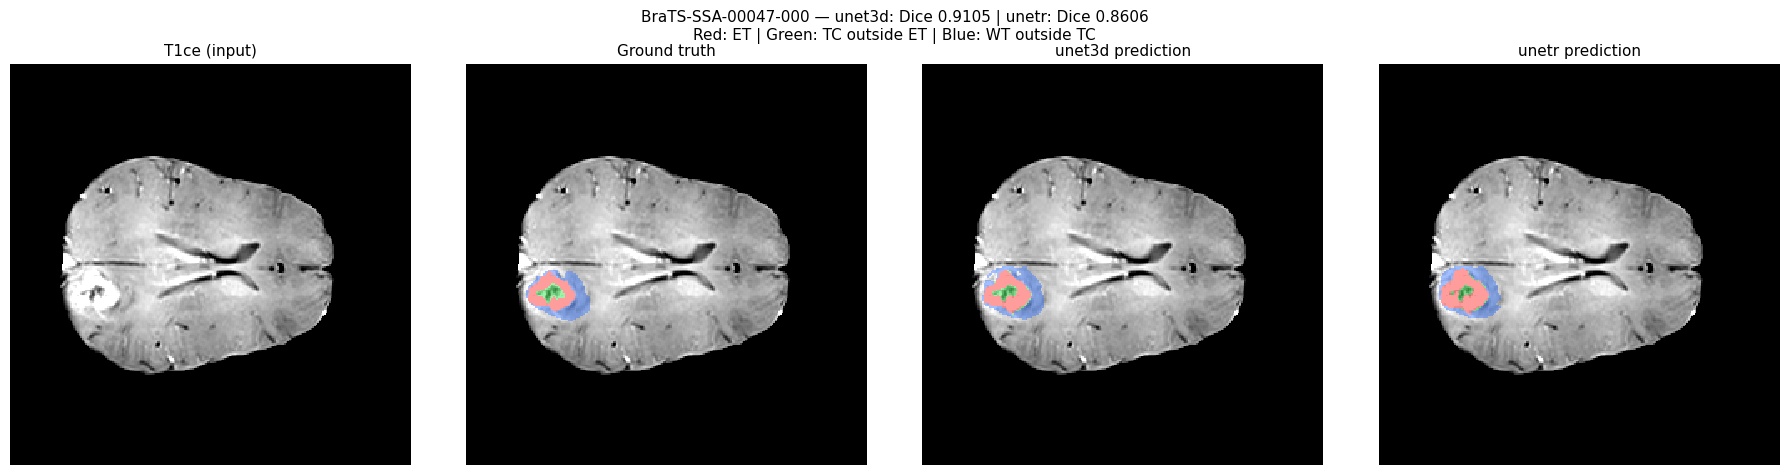

figure saved: /kaggle/working/figures/BraTS-SSA-00047-000.png


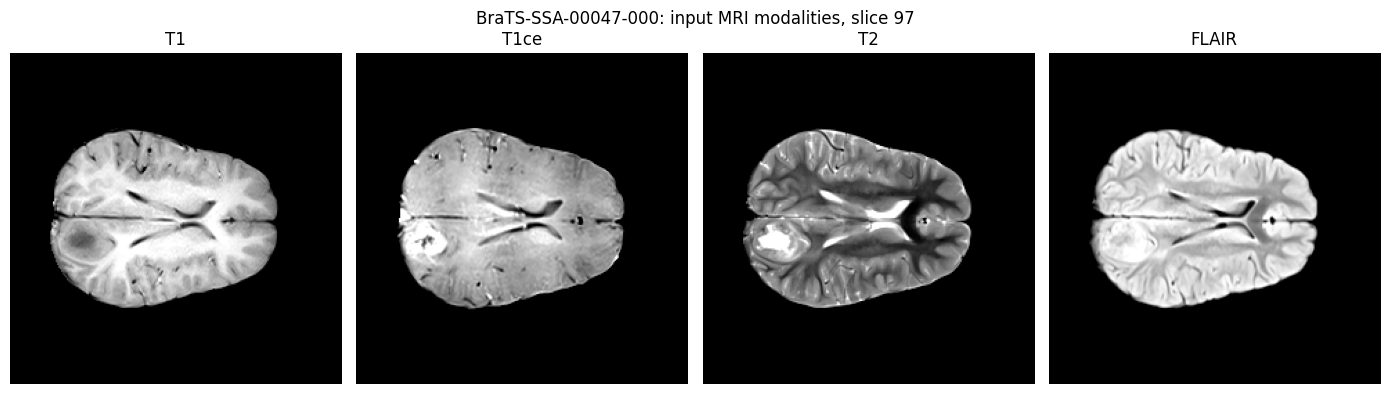

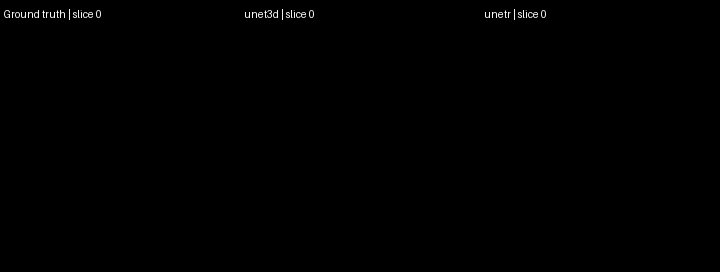

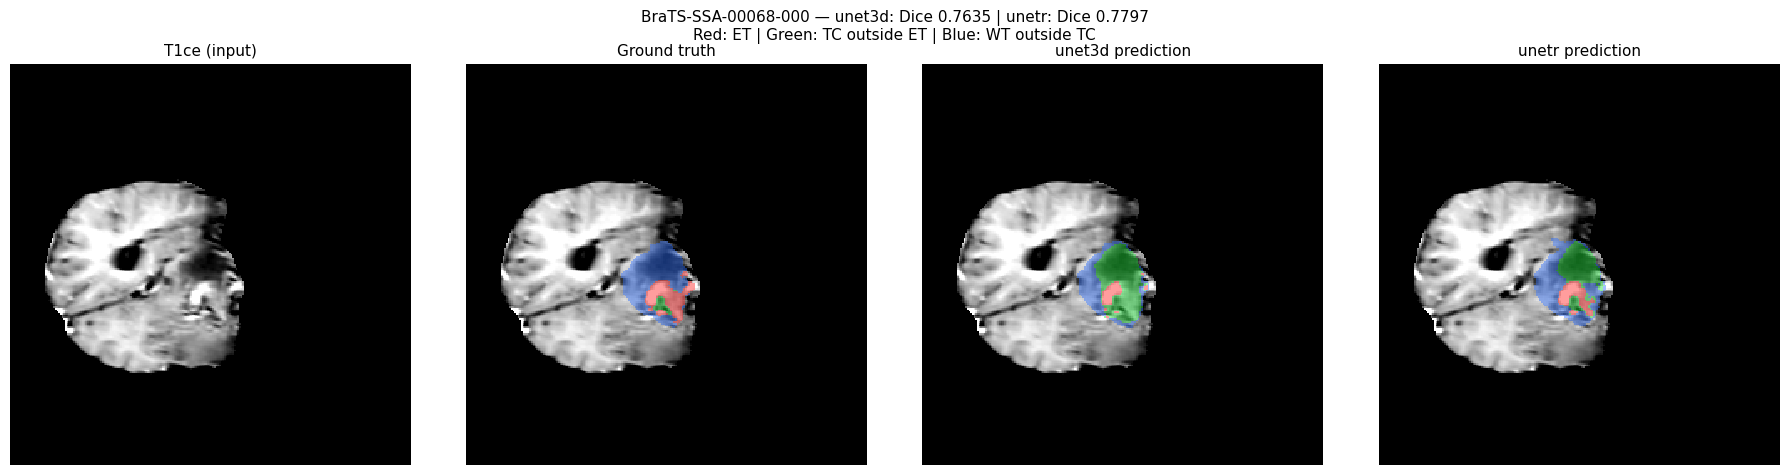

figure saved: /kaggle/working/figures/BraTS-SSA-00068-000.png


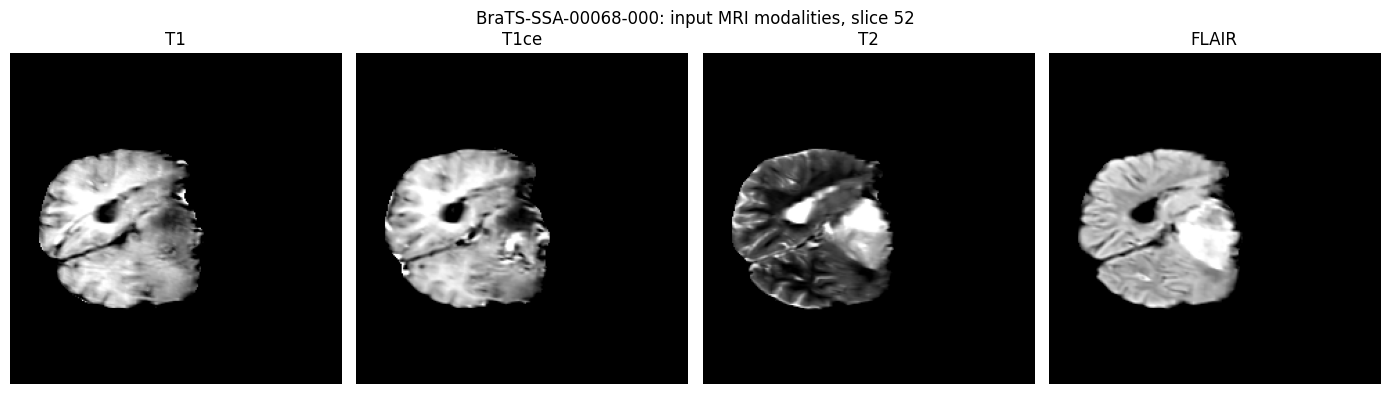

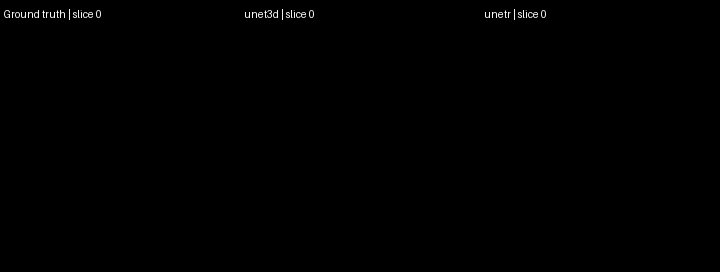

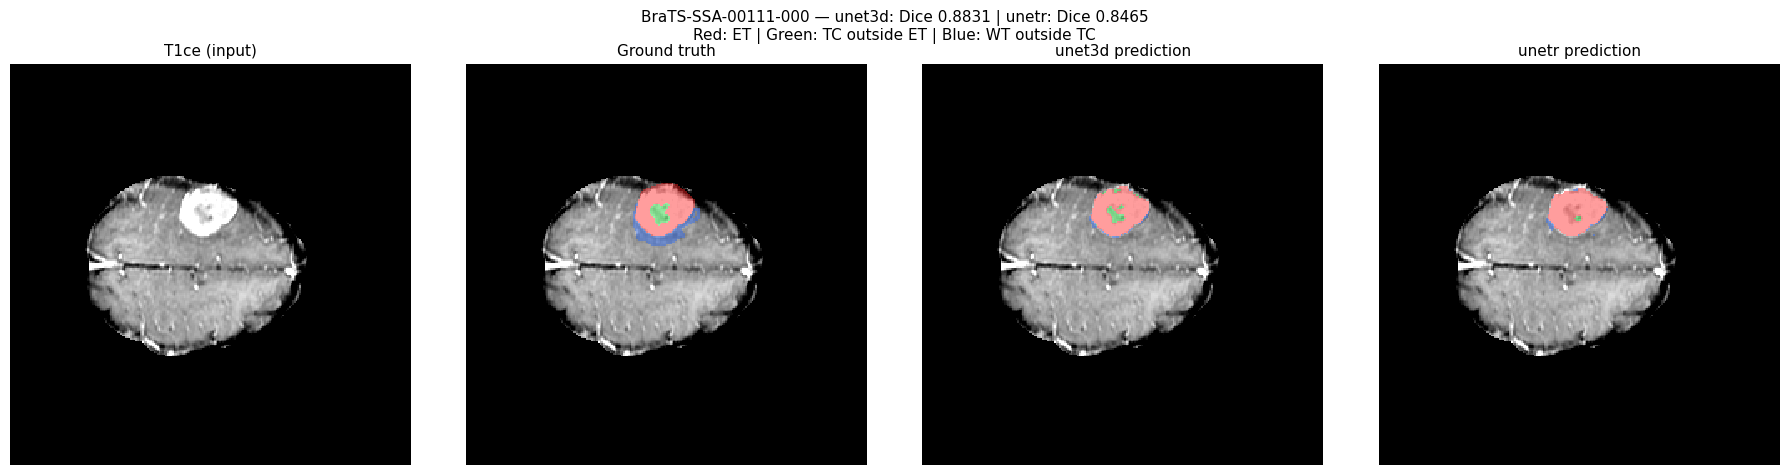

figure saved: /kaggle/working/figures/BraTS-SSA-00111-000.png


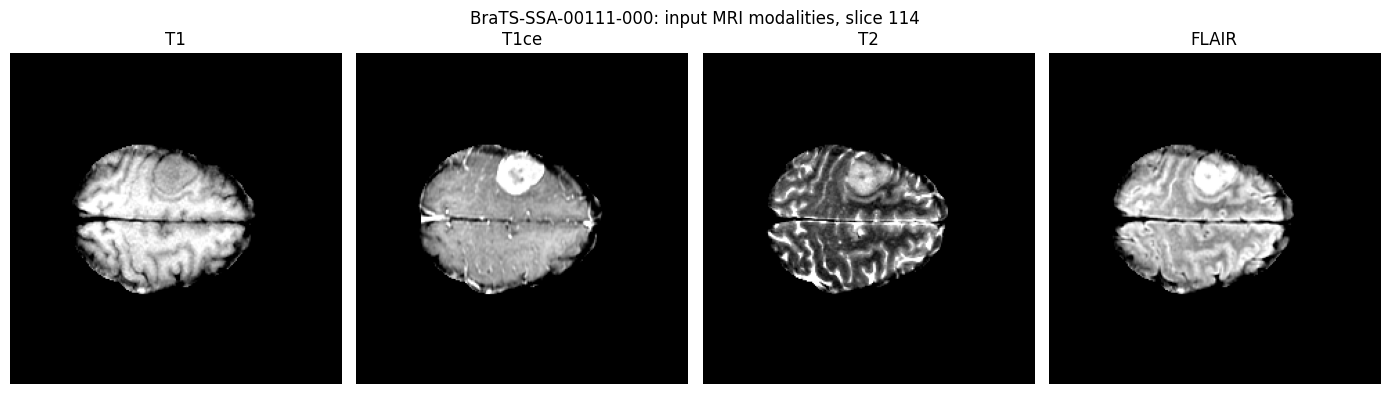

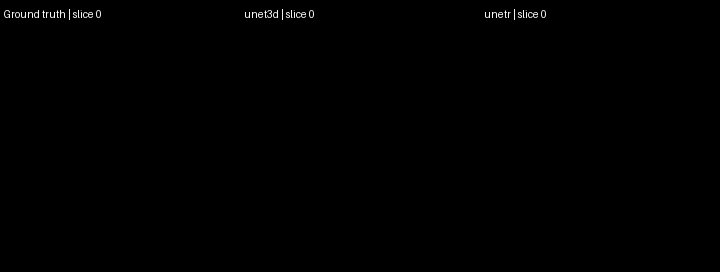

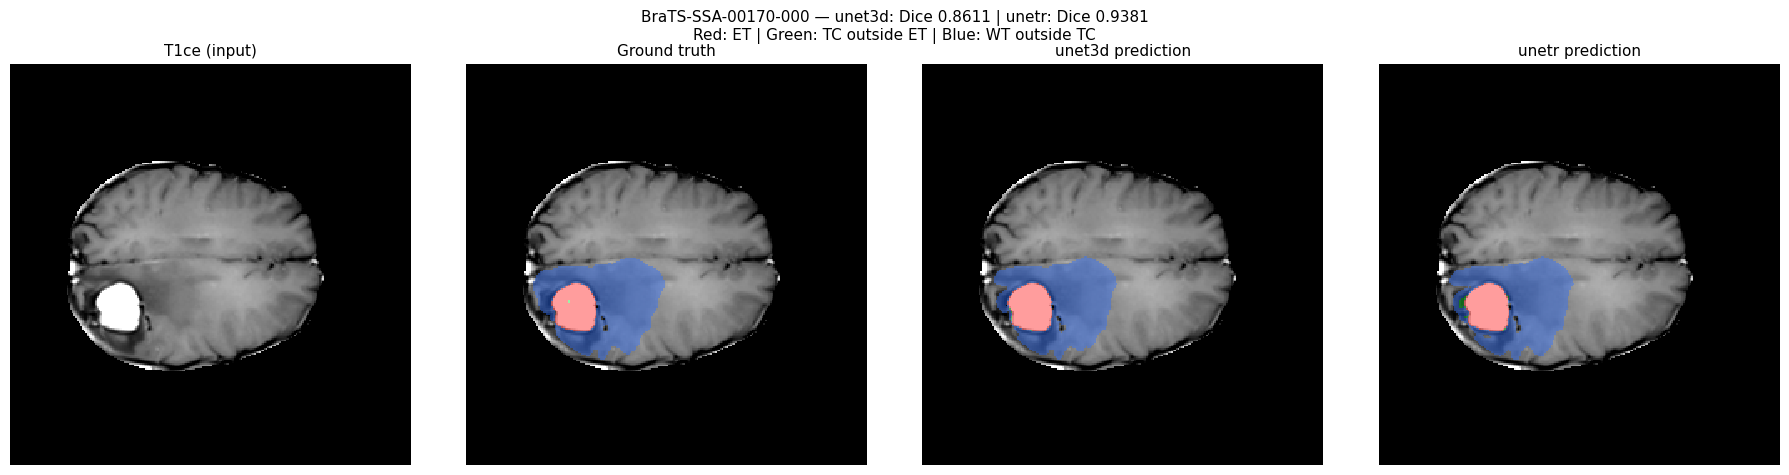

figure saved: /kaggle/working/figures/BraTS-SSA-00170-000.png


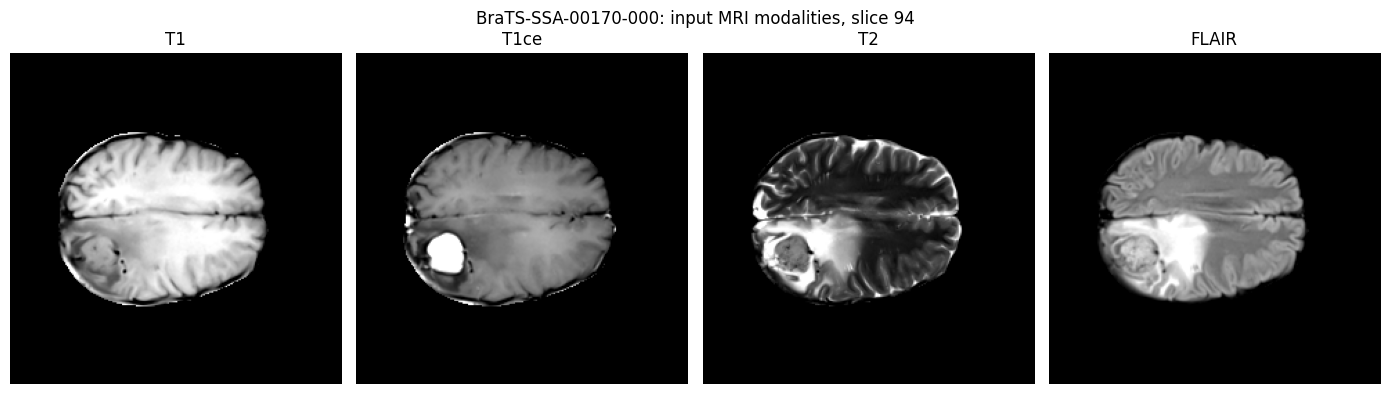

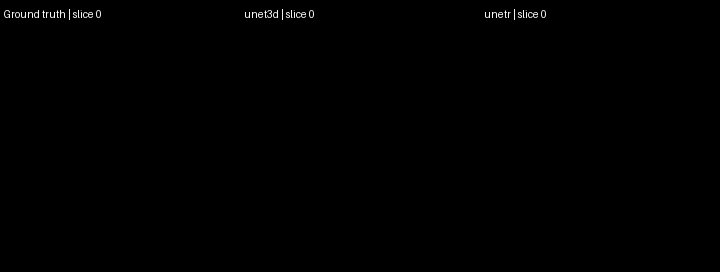

In [13]:
# ============================================================
# 10. FIGURES FOR THE SELECTED CASES
# ============================================================
import os
os.makedirs("/kaggle/working/figures", exist_ok=True)

for idx, (case_id, payload) in enumerate(pred_cache.items()):
    preds = {k: v for k, v in payload.items() if not k.startswith("__")}
    image = payload["__image__"]
    gt = payload["__gt__"]
    dice_txt = " | ".join(
        f"{n}: Dice {LONG[(LONG['case_id'] == case_id) & (LONG['model'] == n)]['dice_mean'].iloc[0]:.4f}"
        for n in preds
    )
    show_case(image, gt, preds,
              title=f"{case_id} — {dice_txt}",
              save_path=f"/kaggle/working/figures/{case_id}.png")
    print(f"figure saved: /kaggle/working/figures/{case_id}.png")

    # Four input modalities on the same tumor-containing slice.
    z = best_slice_index(gt)
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for channel, (ax, name) in enumerate(zip(axes, ["T1", "T1ce", "T2", "FLAIR"])):
        ax.imshow(to_gray(image[channel, :, :, z]), cmap="gray")
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle(f"{case_id}: input MRI modalities, slice {z}")
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/figures/{case_id}_modalities.png", dpi=110)
    plt.show()
    plt.close(fig)

    # Animated axial traversal of the 3D volume (not a surface rendering).
    from PIL import Image, ImageDraw
    from IPython.display import Image as DisplayImage, display
    frames = []
    for z in range(0, image.shape[-1], 3):
        base = image[1, :, :, z]
        tiles = [("Ground truth", gt)] + list(preds.items())
        arrays = [(overlay(base, masks[:, :, :, z]) * 255).astype(np.uint8)
                  for _, masks in tiles]
        canvas = Image.new("RGB", (sum(a.shape[1] for a in arrays), arrays[0].shape[0]+32))
        draw = ImageDraw.Draw(canvas)
        x = 0
        for (name, _), array in zip(tiles, arrays):
            canvas.paste(Image.fromarray(array), (x, 32))
            draw.text((x+4, 8), f"{name} | slice {z}", fill="white")
            x += array.shape[1]
        frames.append(canvas)
    gif_path = f"/kaggle/working/figures/{case_id}.gif"
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=120, loop=0)
    display(DisplayImage(filename=gif_path))
    del frames


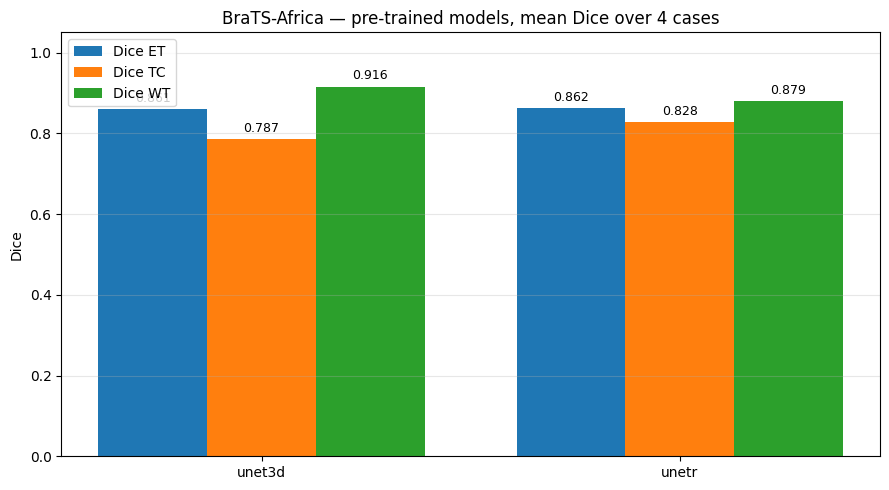

In [14]:
# ============================================================
# 11. SUMMARY CHART — Dice per region, both models
# ============================================================
import matplotlib.pyplot as plt

models = list(summary.index)
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(models))
width = 0.26
for j, region in enumerate(["ET", "TC", "WT"]):
    vals = [summary.loc[m, f"dice_{region}"] for m in models]
    bars = ax.bar(x + (j - 1) * width, vals, width, label=f"Dice {region}")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}",
                ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel("Dice")
ax.set_ylim(0, 1.05)
ax.set_title(f"BraTS-Africa — pre-trained models, mean Dice over {len(LONG)//len(models)} cases")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/dice_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


## 9. Notes

* **No training anywhere in this notebook** — only forward passes through the
  pre-trained checkpoints released with the
  [Brain_Tumor_Benchmark](https://github.com/MohanadMahran/Brain_Tumor_Benchmark) repo.
* **Pre-trained models**
  * 3D U-Net — [MohanadKombar/brain-tumor-unet3d-brats](https://huggingface.co/MohanadKombar/brain-tumor-unet3d-brats)
  * UNETR — [MohanadKombar/brain-tumor-unetr-brats](https://huggingface.co/MohanadKombar/brain-tumor-unetr-brats)
* **Regions** — ET = label 4, TC = labels 1+4, WT = labels 1+2+4; label 3 is
  automatically remapped to 4.
* **Inference protocol** — MONAI sliding window when available, otherwise the
  tested PyTorch fallback; 128^3 ROI, 25% overlap, Gaussian blending, AMP on GPU.
* **Dataset** — [yakunokamizen/brats-africa](https://www.kaggle.com/datasets/yakunokamizen/brats-africa)
  (BraTS-Africa, 146 cases with segmentations). This is a small real-data
  evaluation sample. Training-set overlap has not been independently excluded;
  these are illustrative sample results, not a reproduced independent benchmark.
  The author's validation scores (UNet3D 0.8694, UNETR 0.8362) are not our results.
* **Label semantics** follow the repository convention (3 mapped to 4).
  Observing numerical label values alone does not verify their biological meaning.
  Confirm this convention against the dataset annotation documentation before
  presenting ET/TC-specific results as validated.
* **HD95** uses NIfTI voxel spacing for nonempty masks. One-sided empty masks
  retain the repository's fixed diagonal penalty; both empty gives Dice=1, HD95=0.
* **Outputs written to `/kaggle/working`** — per-case CSV, summary CSV, and PNG
  figures for the visual comparison.

## 10. Export and completion check

The HTML report combines the measured tables, patient images and animations.
Only a completed run writes `SUCCESS.json`. Checkpoint validation scores are
not used as results in this report. The four patients are a demonstration
sample, not evidence of clinical validity or a reproduction of the author's
UPenn-GBM benchmark.

In [15]:
import html
from IPython.display import FileLink, display
output = Path("/kaggle/working")
assert len(LONG) == len(selected) * 2
assert np.isfinite(LONG[METRIC_KEYS].to_numpy()).all()
assert LONG[["dice_ET", "dice_TC", "dice_WT"]].ge(0).all().all()
assert LONG[["dice_ET", "dice_TC", "dice_WT"]].le(1).all().all()
parts = ["<!doctype html><html><head><meta charset='utf-8'><title>Pretrained brain tumor segmentation</title>",
         "<style>body{font:16px system-ui;max-width:1250px;margin:40px auto;padding:20px;background:#f6f8fb;color:#172033}img{max-width:100%;background:white}table{border-collapse:collapse;font-size:13px}td,th{padding:8px;border:1px solid #ccd3df}h1,h2{color:#183d65}</style></head><body>",
         "<h1>Pretrained UNet3D vs UNETR on real BraTS-Africa MRI</h1>",
         f"<p>{len(selected)} seeded sample cases; no training or fine-tuning. Device: {DEVICE}. Both models use the same patients, preprocessing and threshold.</p>",
         "<h2>Measured results</h2>", summary.round(4).to_html(),
         "<p>Dice: higher is better. HD95: lower is better, in millimetres. Scores are measured on these cases, not copied from the model author's validation results.</p>",
         "<img src='dice_comparison.png' alt='Dice comparison'>",
         "<h2>Per-patient results</h2>", LONG.round(4).to_html(index=False)]
for case_id in pred_cache:
    parts += [f"<h2>{html.escape(case_id)}</h2>",
              f"<img src='figures/{case_id}_modalities.png' alt='Four MRI modalities'>",
              f"<img src='figures/{case_id}.png' alt='Ground truth and model overlays'>",
              f"<img src='figures/{case_id}.gif' alt='Animated axial slice comparison'>"]
parts += ["<h2>Scope and limitations</h2><p>Small seeded sample; not a clinical diagnostic tool. No independent training-data overlap audit was performed. Labels follow the repository mapping of 3 to 4 for enhancing tumor. One-sided empty masks receive the repository fixed HD95 penalty. Animated images traverse slices of a 3D scan; they are not surface reconstructions.</p>",
          "<h2>Sources</h2><p><a href='https://github.com/MohanadMahran/Brain_Tumor_Benchmark'>Original implementation</a> | <a href='https://www.kaggle.com/datasets/yakunokamizen/brats-africa'>Dataset</a> | <a href='https://pubs.rsna.org/doi/10.1148/ryai.240528'>BraTS-Africa dataset paper</a></p></body></html>"]
(output / "report.html").write_text("\n".join(parts), encoding="utf-8")
required = ["brats_africa_results.csv", "brats_africa_summary.csv", "selected_cases.csv",
            "cohort_summary.csv", "run_metadata.json", "report.html", "dice_comparison.png"]
required += [f"figures/{cid}{suffix}" for cid in pred_cache for suffix in [".png", ".gif", "_modalities.png"]]
assert all((output / name).is_file() and (output / name).stat().st_size > 0 for name in required)
(output / "SUCCESS.json").write_text(json.dumps({"cases": len(selected), "model_case_evaluations": len(LONG), "artifacts": required}, indent=2))
print("END-TO-END COMPLETE: real-case metrics, images, animations and report verified.")
display(FileLink(str(output / "report.html")))


END-TO-END COMPLETE: real-case metrics, images, animations and report verified.


/kaggle/working/report.html